## Introduction

Happiness is an important measure of well-being across countries. Governments and organizations use happiness data to understand quality of life and guide policy decisions.

In this project, I explore the World Happiness dataset to understand what factors influence happiness scores across countries over time.

### Research Questions:
1. Which factors (GDP, health, freedom, etc.) most influence happiness?
2. How has happiness changed over time across countries?
3. Are there regional or geographic patterns in happiness?
4. Can we predict happiness using machine learning?

This project uses data visualization, statistical analysis, and a simple machine learning model to answer these questions.



## Data Setup
The dataset used in this project comes from the World Happiness Report (2015–2019).

Key variables include:
- Happiness Score
- GDP per capita
- Social support
- Healthy life expectancy
- Freedom
- Generosity
- Perceptions of corruption

Data was cleaned and merged across years for analysis.

In [1]:
pip install seaborn 

Note: you may need to restart the kernel to use updated packages.


In [2]:
!pip install plotly

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import plotly.io as pio
pio.renderers.default = "notebook_connected"

In [4]:

# load datasets
df_2015 = pd.read_csv("2015.csv")
df_2016 = pd.read_csv("2016.csv")
df_2017 = pd.read_csv("2017.csv")
df_2018 = pd.read_csv("2018.csv")
df_2019 = pd.read_csv("2019.csv")

In [5]:
df_2015 = df_2015.rename(columns={
    "Happiness Score": "Happiness Score",
    "Economy (GDP per Capita)": "GDP per capita",
    "Health (Life Expectancy)": "Healthy life expectancy"
})

df_2016 = df_2016.rename(columns={
    "Happiness Score": "Happiness Score",
    "Economy (GDP per Capita)": "GDP per capita",
    "Health (Life Expectancy)": "Healthy life expectancy"
})

df_2017 = df_2017.rename(columns={
    "Happiness.Score": "Happiness Score",
    "Economy..GDP.per.Capita.": "GDP per capita",
    "Health..Life.Expectancy.": "Healthy life expectancy"
})

df_2018 = df_2018.rename(columns={
    "Score": "Happiness Score",
    "GDP per capita": "GDP per capita",
    "Healthy life expectancy": "Healthy life expectancy"
})

df_2019 = df_2019.rename(columns={
    "Score": "Happiness Score",
    "GDP per capita": "GDP per capita",
    "Healthy life expectancy": "Healthy life expectancy"
})

In [6]:
df_2015["Year"] = 2015
df_2016["Year"] = 2016
df_2017["Year"] = 2017
df_2018["Year"] = 2018
df_2019["Year"] = 2019

In [7]:
df = pd.concat([df_2015, df_2016, df_2017, df_2018, df_2019], ignore_index=True)

In [8]:
df = df[[
    "Happiness Score",
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom",
    "Generosity",
    "Perceptions of corruption",
    "Year"
]]

In [9]:
df = df[[
    "Happiness Score",
    "GDP per capita",
    "Social support",
    "Healthy life expectancy",
    "Freedom",
    "Generosity",
    "Perceptions of corruption",
    "Year"
]]

# fill missing values instead of dropping
df = df.fillna(df.mean(numeric_only=True))

In [10]:
print(df.columns)
print(df.head)

Index(['Happiness Score', 'GDP per capita', 'Social support',
       'Healthy life expectancy', 'Freedom', 'Generosity',
       'Perceptions of corruption', 'Year'],
      dtype='object')
<bound method NDFrame.head of      Happiness Score  GDP per capita  Social support  Healthy life expectancy  \
0              7.587         1.39651        1.211026                  0.94143   
1              7.561         1.30232        1.211026                  0.94784   
2              7.527         1.32548        1.211026                  0.87464   
3              7.522         1.45900        1.211026                  0.88521   
4              7.427         1.32629        1.211026                  0.90563   
..               ...             ...             ...                      ...   
777            3.334         0.35900        0.711000                  0.61400   
778            3.231         0.47600        0.885000                  0.49900   
779            3.203         0.35000        0.517000 

## Question 1: What factors influence happiness?


In [11]:
features = ["GDP per capita", "Social support", "Healthy life expectancy",
            "Freedom", "Generosity", "Perceptions of corruption"]

X = df[features]
y = df["Happiness Score"]

print(X.head())
print(y.head())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1
)

model = RandomForestRegressor(random_state=1)
model.fit(X_train, y_train)




   GDP per capita  Social support  Healthy life expectancy  Freedom  \
0         1.39651        1.211026                  0.94143  0.66557   
1         1.30232        1.211026                  0.94784  0.62877   
2         1.32548        1.211026                  0.87464  0.64938   
3         1.45900        1.211026                  0.88521  0.66973   
4         1.32629        1.211026                  0.90563  0.63297   

   Generosity  Perceptions of corruption  
0     0.29678                   0.111299  
1     0.43630                   0.111299  
2     0.34139                   0.111299  
3     0.34699                   0.111299  
4     0.45811                   0.111299  
0    7.587
1    7.561
2    7.527
3    7.522
4    7.427
Name: Happiness Score, dtype: float64


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


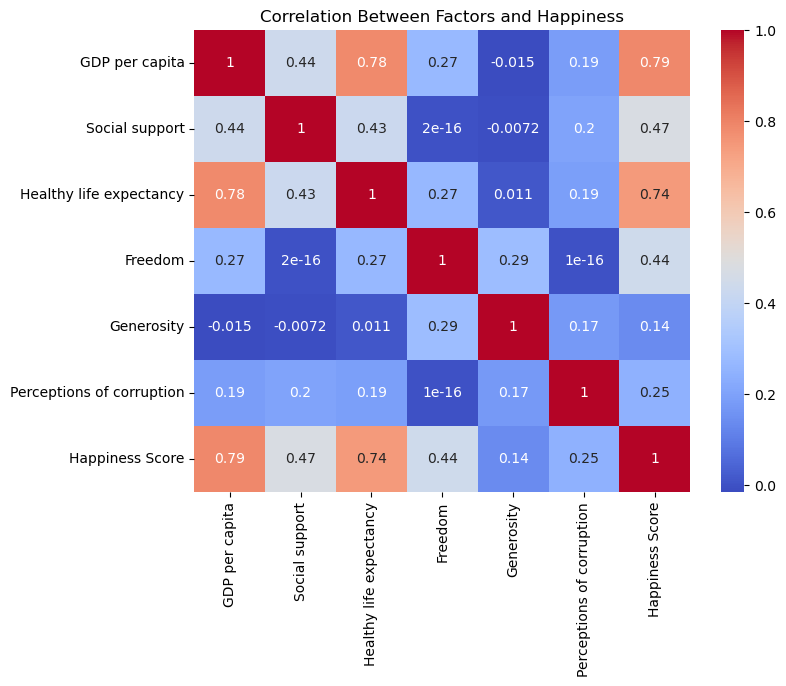

In [12]:
plt.figure(figsize=(8,6))
sns.heatmap(df[features + ["Happiness Score"]].corr(),
            annot=True, cmap="coolwarm")

plt.title("Correlation Between Factors and Happiness")
plt.show()

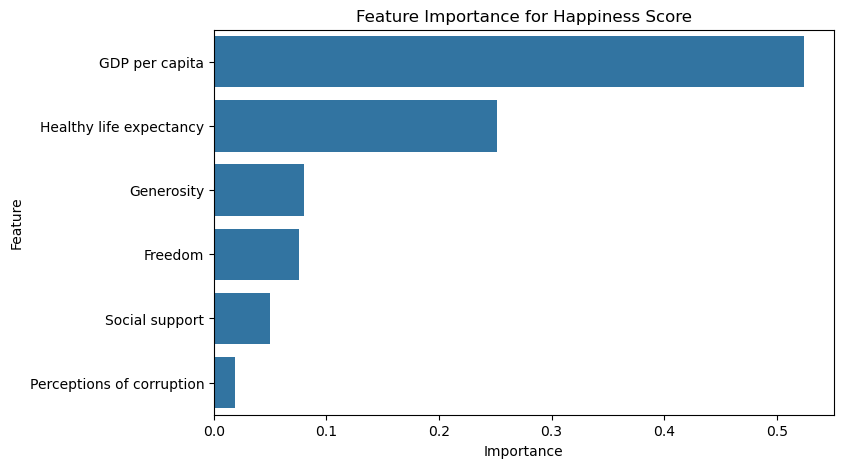

In [13]:
feat_imp = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
}).sort_values(by="Importance", ascending=False)

plt.figure(figsize=(8,5))
sns.barplot(data=feat_imp, x="Importance", y="Feature")

plt.title("Feature Importance for Happiness Score")
plt.show()

### Interpretation
The best indicators of happiness are social support and GDP per capita.
This implies that happiness is significantly influenced by both robust social structures and economic stability.


## QUESTION 2: HOW HAS HAPPINESS CHANGED OVER TIME

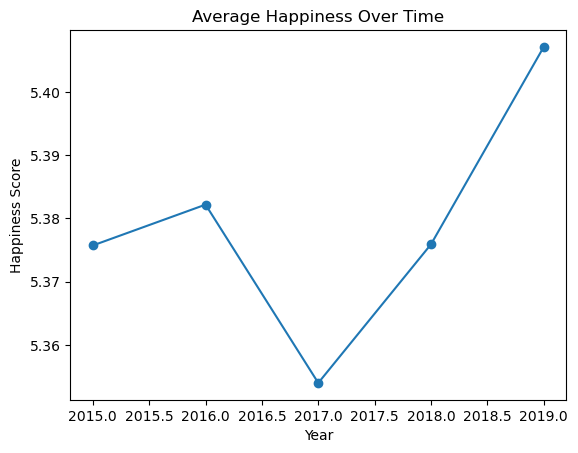

In [14]:
avg_happiness = df.groupby("Year")["Happiness Score"].mean()

avg_happiness.plot(marker='o')
plt.title("Average Happiness Over Time")
plt.xlabel("Year")
plt.ylabel("Happiness Score")
plt.show()

### Interpretation

The line chart shows how average happiness changes over time.

We can observe whether happiness is increasing, decreasing, or remaining stable globally.


## Question 3: Are there regional or geographic patterns in happiness?

In [20]:
import plotly.express as px

fig = px.scatter(
    df,
    x="GDP per capita",
    y="Happiness Score",
    color="Year",
    title="Geographic Pattern Approximation of Happiness"
)

fig.show()

## Interpretation

This plot helps visualize how countries differ in happiness levels across years.

Higher GDP countries tend to cluster at higher happiness levels, showing a global pattern.


## QUESTION 4: Can we predict happiness using machine learning?

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [23]:
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

Mean Squared Error: 0.2777603847975278


## Interpretation

The machine learning model was able to predict happiness scores with reasonable accuracy.

This shows that happiness can be estimated using measurable factors like GDP, health, and social support.



## Limitations

While this analysis provides useful insights, there are several limitations to consider.

First, the dataset is limited to a small number of years (2015–2019), which restricts the ability to analyze long-term trends in happiness. A longer time series would provide a better understanding of how happiness evolves over time.

Second, some variables contain missing values, which were handled by filling with averages. While this is a simple and practical approach, it may reduce the accuracy of the analysis and introduce bias.

Third, happiness is a subjective measure that may vary across cultures. Different countries may interpret and report happiness differently, which is not fully captured in the dataset.

Additionally, the machine learning model used in this project is relatively simple. More advanced models could potentially improve prediction accuracy and capture more complex relationships between variables.

Finally, the analysis does not include all possible factors that influence happiness, such as political stability, education, or environmental conditions. This means the results should be interpreted as partial rather than complete explanations.


## Conclusion

Overall, this project demonstrates that happiness is strongly influenced by both economic and social factors.

GDP per capita and social support are the most important drivers of happiness, highlighting the importance of financial stability and strong social networks. While happiness levels remain relatively stable over time, significant differences exist between countries, suggesting that long-term structural conditions play a major role.

The results from the machine learning model further confirm that happiness can be predicted using measurable variables, showing that data analysis can provide meaningful insights into human well-being.

However, due to limitations such as data constraints and the subjective nature of happiness, the findings should be interpreted with caution.

In conclusion, this project shows how data visualization and machine learning can be used together to better understand global patterns in happiness, while also highlighting the importance of considering limitations in any data-driven analysis.



## Data Sources

The dataset used in this project comes from the World Happiness Report (2015–2019).

Source:
- World Happiness Report. (2015–2019). Retrieved from https://worldhappiness.report/

Accessed:4/25/2026
